# 07 · Exploratory analysis: river, snow and vegetation

**Person 2 (Leora).** The same first steps the midsem notebook (`00_midsem/notebooks/01_eda_stationarity_arma.ipynb`) applied to the elk counts, applied here to the new Part 2 datasets, before any modelling in notebooks 12 and 11.

| Section | Dataset | Steps |
|---|---|---|
| 0 | All | Load, completeness, summary statistics |
| 1 | River: USGS 06191500, Yellowstone River at Corwin Springs | Time plots, distribution, seasonal pattern, smoothing and trend, stationarity, ACF/PACF, ARMA identification |
| 2 | Snow: NRCS SNOTEL 670 Northeast Entrance, 384 Canyon, 683 Parker Peak | Same steps, plus agreement between stations |
| 3 | Vegetation: Landsat NDVI, riverside and slope polygons on three streams | Same steps |
| 4 | All annual series together | Correlations in levels and in differences |
| 5 | Takeaways | |

**Tests used throughout** (as in the midsem notebook):
- **ADF** (null: unit root, i.e. non-stationary), run with 0, 1 and 2 lagged differences; counted as rejecting if it rejects at 2 of the 3.
- **KPSS** (null: stationary around a constant). A second KPSS run (null: stationary around a straight-line trend) separates a series that wanders from one that just trends.
- A series is called **stationary** only when ADF rejects and KPSS does not.
- **ARMA identification:** candidates suggested by the ACF/PACF are fitted; the chosen model is the simplest one whose terms are all significant and whose residuals are white noise (Ljung–Box p > 0.05).

Run order for Part 2: **07 → 12 → 11**. This notebook reads only raw files and the SNOTEL products from `scripts/build_severity_index.py`; it writes nothing that the other notebooks need.

In [1]:
import csv
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
REINTRO = 1995
PAIRS = ["Lamar", "Soda Butte", "Blacktail"]
COL = {"Lamar": "C0", "Soda Butte": "C1", "Blacktail": "C2"}

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"P2_EDA_{name}.png", dpi=200)


def stationarity(x, name):
    """ADF at lags 0, 1, 2 plus KPSS (level and trend). Same rule as the midsem notebook."""
    x = pd.Series(x).dropna()
    adf = [adfuller(x, maxlag=l, autolag=None)[1] for l in (0, 1, 2)]
    kp_c = kpss(x, regression="c", nlags="auto")[1]
    kp_t = kpss(x, regression="ct", nlags="auto")[1]
    adf_rej = sum(p < 0.05 for p in adf) >= 2
    if adf_rej and kp_c >= 0.05:
        verdict = "stationary"
    elif not adf_rej and kp_c < 0.05:
        verdict = "trend-stationary" if kp_t >= 0.05 else "non-stationary"
    else:
        verdict = "trend-stationary" if (kp_c < 0.05 and kp_t >= 0.05) else "unclear (tests disagree)"
    return {"series": name, "n": len(x), "ADF p (lag 0, 1, 2)": ", ".join(f"{p:.3f}" for p in adf),
            "KPSS p (level)": round(kp_c, 3), "KPSS p (trend)": round(kp_t, 3), "verdict": verdict}


def acf_pacf(y, title, lags, name):
    y = pd.Series(y).dropna()
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].plot(y.index, y.values, lw=0.8 if len(y) > 200 else 1.2, color="0.3", marker="" if len(y) > 200 else ".")
    ax[0].set_title(title)
    plot_acf(y, lags=lags, ax=ax[1]); ax[1].set_title("ACF")
    plot_pacf(y, lags=lags, ax=ax[2], method="ywm"); ax[2].set_title("PACF")
    save(fig, name)


def arma_id(y, name, cands=((0, 0), (1, 0), (2, 0), (0, 1), (0, 2), (1, 1))):
    """Fit candidate ARMA(p, q) models; pick the simplest with significant terms and white-noise residuals."""
    y = pd.Series(y).dropna().reset_index(drop=True)
    rows = []
    for p_, q_ in cands:
        m = ARIMA(y, order=(p_, 0, q_), trend="c").fit()
        terms = [k for k in m.params.index if k.startswith(("ar.", "ma."))]
        lb = acorr_ljungbox(m.resid, lags=[min(10, len(y) // 5)], model_df=p_ + q_).lb_pvalue.iloc[0]
        rows.append({"series": name, "model": f"ARMA({p_},{q_})", "AIC": round(m.aic, 1), "BIC": round(m.bic, 1),
                     "largest term p": round(max([m.pvalues[k] for k in terms], default=0), 3),
                     "all terms significant": all(m.pvalues[k] < 0.05 for k in terms),
                     "Ljung–Box p": round(lb, 3), "white-noise residuals": lb > 0.05, "order": p_ + q_})
    t = pd.DataFrame(rows)
    ok = t[t["all terms significant"] & t["white-noise residuals"]]
    chosen = ok.sort_values(["order", "BIC"]).iloc[0]["model"] if len(ok) else "none passes"
    t["chosen"] = t["model"] == chosen
    return t.drop(columns="order"), chosen

## 0. Data and completeness

| File | Source | Frequency | Variables |
|---|---|---|---|
| `usgs_06191500_daily_flow.txt` | USGS NWIS, gauge 06191500 | daily | mean discharge (cubic feet per second, cfs) |
| `snotel_northeast_entrance.csv`, `snotel_canyon.csv`, `snotel_parker_peak.csv` | NRCS SNOTEL 670, 384, 683 | daily | snow water equivalent (in), snow depth (in), mean air temperature (°F, converted to °C here) |
| `winter_severity_index.csv`, `monthly_temperature.csv` | built from SNOTEL by `scripts/build_severity_index.py` | annual, monthly | severity index, melt-out anomaly, monthly mean temperature |
| `ndvi_lamar_sodabutte.csv`, `ndvi_blacktail.csv` | Climate Engine, Landsat 5/7/8/9, 30 m | each satellite image | mean NDVI over six polygons |

In [2]:
# --- river ---
raw = pd.read_csv(RAW / "usgs_06191500_daily_flow.txt", sep="\t", comment="#", dtype=str)
raw = raw[raw["agency_cd"] == "USGS"]
qcol = [c for c in raw.columns if c.endswith("_00003")][0]
flow = pd.DataFrame({"Q": pd.to_numeric(raw[qcol], errors="coerce").values, "code": raw[qcol + "_cd"].values},
                    index=pd.to_datetime(raw["datetime"])).asfreq("D")
flow["wy"] = flow.index.year + (flow.index.month >= 10)
flow["dowy"] = (flow.index - pd.to_datetime((flow["wy"] - 1).astype(str) + "-10-01").values).days + 1
n_days, expected = flow.groupby("wy")["Q"].count(), flow.groupby("wy").size()
WY = [w for w in n_days[(n_days == expected) & (expected >= 365)].index if 1911 <= w <= 2026]
f = flow[flow.wy.isin(WY)].copy()

# --- snow ---
def load_snotel(path):
    d = pd.read_csv(path, comment="#", parse_dates=["Date"]).set_index("Date")
    d.columns = ["SWE", "DEPTH", "TAVG"][: d.shape[1]]
    d.loc[d["TAVG"] < -60, "TAVG"] = np.nan
    d["TAVG"] = (d["TAVG"] - 32) * 5 / 9                     # °F → °C
    d["wy"] = d.index.year + (d.index.month >= 10)
    d["dowy"] = (d.index - pd.to_datetime((d["wy"] - 1).astype(str) + "-10-01").values).days + 1
    return d

STN = {"Northeast Entrance": "snotel_northeast_entrance.csv", "Canyon": "snotel_canyon.csv", "Parker Peak": "snotel_parker_peak.csv"}
snow = {k: load_snotel(RAW / v) for k, v in STN.items()}
sev = pd.read_csv(PROC / "winter_severity_index.csv", index_col="Year")
mtemp = pd.read_csv(PROC / "monthly_temperature.csv", index_col="Month", parse_dates=True)

# --- vegetation ---
def load_ce(path, names):
    rows = [r for r in csv.reader(open(path)) if r and r[0][:2] in ("19", "20")]
    full = [r for r in rows if len(r) == len(names) + 1]
    d = pd.DataFrame([[pd.Timestamp(r[0])] + [float(x) for x in r[1:]] for r in full], columns=["date"] + names).set_index("date")
    return d, len(rows), len(full)

va, na_all, na_full = load_ce(RAW / "ndvi_lamar_sodabutte.csv", ["Lamar|riverside", "Lamar|slope", "Soda Butte|riverside", "Soda Butte|slope"])
vb, nb_all, nb_full = load_ce(RAW / "ndvi_blacktail.csv", ["Blacktail|riverside", "Blacktail|slope"])
long = pd.concat([va.stack(), vb.stack()]).rename("ndvi").reset_index()
long.columns = ["date", "region", "ndvi"]
long[["pair", "side"]] = long["region"].str.split("|", expand=True)
n_artefact = (~long["ndvi"].between(-0.2, 0.95)).sum()
long = long[long["ndvi"].between(-0.2, 0.95)].copy()
long["year"], long["month"], long["doy"] = long.date.dt.year, long.date.dt.month, long.date.dt.dayofyear

# --- completeness table ---
rows = [{"dataset": "River flow (USGS 06191500)", "period used": f"WY {WY[0]}–{WY[-1]}", "records": len(f),
         "missing": int(f["Q"].isna().sum()), "notes": f"water years 1895–1910 missing in source; {int((f.code.str.contains('e', na=False)).sum())} estimated, {int((f.code.str.startswith('P', na=False)).sum())} provisional days"}]
for k, d in snow.items():
    span = d.loc[d["SWE"].first_valid_index():]
    rows.append({"dataset": f"SNOTEL {k}: snow water equivalent", "period used": f"{span.index.min().date()} to {span.index.max().date()}",
                 "records": len(span), "missing": int(span["SWE"].isna().sum()), "notes": f"temperature missing on {int(span['TAVG'].isna().sum())} days"})
rows.append({"dataset": "NDVI Lamar + Soda Butte (4 polygons)", "period used": f"{va.index.min().date()} to {va.index.max().date()}",
             "records": na_all, "missing": na_all - na_full, "notes": "missing = partial rows (cloud-masked polygons), dropped"})
rows.append({"dataset": "NDVI Blacktail (2 polygons)", "period used": f"{vb.index.min().date()} to {vb.index.max().date()}",
             "records": nb_all, "missing": nb_all - nb_full, "notes": f"plus {n_artefact} values outside −0.2 to 0.95 dropped across both files"})
completeness = pd.DataFrame(rows).set_index("dataset")
completeness.to_csv(TAB / "P2_eda_completeness.csv")
completeness

,period used,records,missing,notes
dataset,,,,
River flow (USGS 06191500),WY 1911–2026,42369,0,water years 1895–1910 missing in source; 794 e...
SNOTEL Northeast Entrance: snow water equivalent,1966-10-01 to 2026-11-09,21955,0,temperature missing on 6478 days
SNOTEL Canyon: snow water equivalent,1980-10-01 to 2026-11-09,16841,6,temperature missing on 4778 days
SNOTEL Parker Peak: snow water equivalent,1980-07-23 to 2026-11-09,16911,365,temperature missing on 2125 days
NDVI Lamar + Soda Butte (4 polygons),1984-05-08 to 2026-11-04,1003,404,missing = partial rows (cloud-masked polygons)...
NDVI Blacktail (2 polygons),1984-05-08 to 2026-11-04,692,102,plus 0 values outside −0.2 to 0.95 dropped acr...


## 1. River flow

### 1.1 Summary statistics and distribution

Daily flow is strongly right-skewed: most days are low, a few snowmelt days are ten times higher. On the log scale the distribution is much closer to symmetric, which is why every model in notebook 12 works with log flow.

                    count     mean      std     min     25%      50%      75%       max
daily flow (cfs)  42369.0  3111.41  3822.12  380.00  958.00  1390.00  3420.00  47200.00
log daily flow    42369.0     7.55     0.91    5.94    6.86     7.24     8.14     10.76

Skewness: raw 2.48, log 0.84


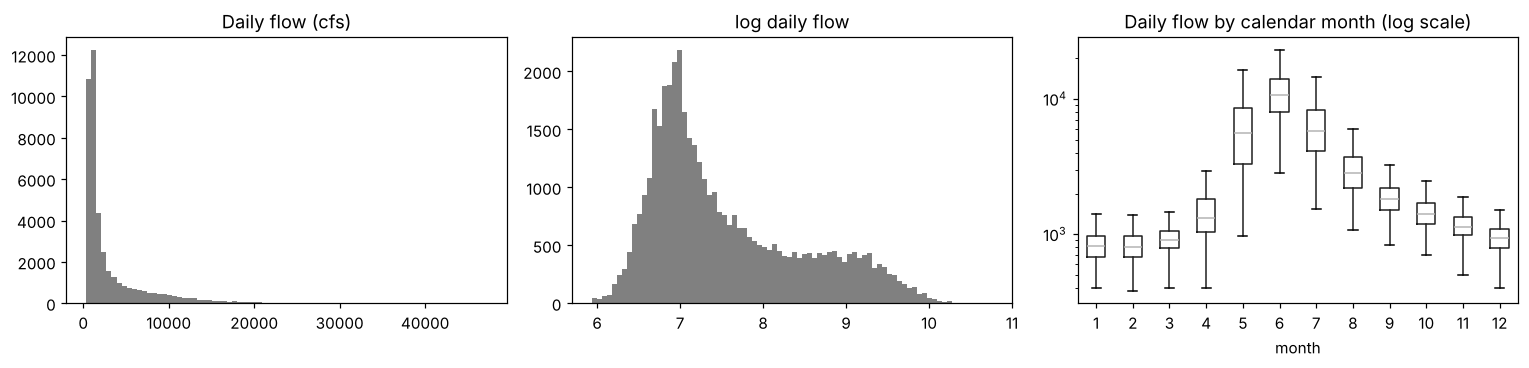

In [3]:
logQ = np.log(f["Q"])
print(pd.DataFrame({"daily flow (cfs)": f["Q"].describe(), "log daily flow": logQ.describe()}).round(2).T.to_string())
print(f"\nSkewness: raw {stats.skew(f['Q']):.2f}, log {stats.skew(logQ):.2f}")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(f["Q"], bins=80, color="0.5"); ax[0].set_title("Daily flow (cfs)")
ax[1].hist(logQ, bins=80, color="0.5"); ax[1].set_title("log daily flow")
f["month"] = f.index.month
f.boxplot(column="Q", by="month", ax=ax[2], grid=False, showfliers=False); ax[2].set_yscale("log")
ax[2].set_title("Daily flow by calendar month (log scale)"); ax[2].set_xlabel("month"); fig.suptitle("")
save(fig, "01_flow_distribution")

### 1.2 Time plots and annual features

The daily series is dominated by one snowmelt pulse a year. To look at change across years, each water year (October–September) is reduced to a few numbers:

- **mean flow**: average daily flow (total water)
- **peak flow**: highest daily flow
- **centre of timing (CT)**: day of the water year by which half the year's flow has passed
- **7-day summer low flow**: lowest 7-day average flow in July–September

Smoothing: an 11-year centred moving average; a straight-line trend is fitted by least squares only to describe the data (formal trend tests are in notebook 12).

         count     mean     std     min      25%      50%      75%      max
mean_Q   116.0   3111.4   684.5  1903.2   2621.3   3050.9   3585.6   5157.6
peak_Q   116.0  17298.7  5679.6  6790.0  13475.0  16750.0  20250.0  47200.0
CT_dowy  116.0    253.4     9.1   229.0    247.0    253.5    260.0    272.0
low7_Q   116.0   1646.5   415.2   854.4   1367.5   1597.9   1951.8   2894.3


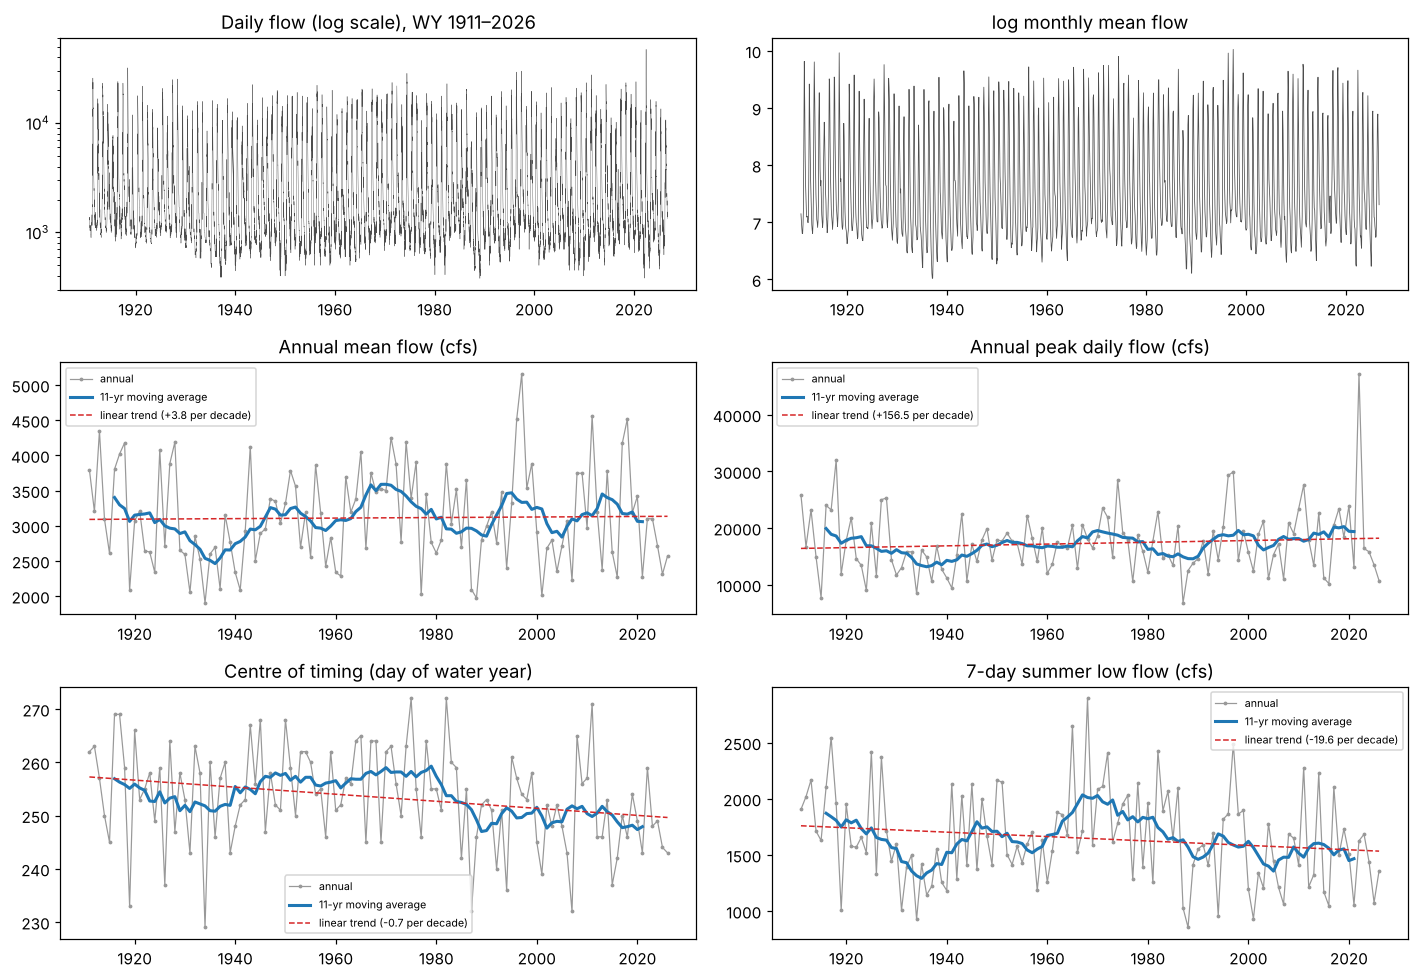

In [4]:
def wy_features(g):
    q = g["Q"].values
    cum = np.cumsum(q) / q.sum()
    summer = g[g.index.month.isin([7, 8, 9])]["Q"].rolling(7).mean()
    return pd.Series({"mean_Q": q.mean(), "peak_Q": q.max(), "CT_dowy": int(np.argmax(cum >= 0.5)) + 1, "low7_Q": summer.min()})

ann = f.groupby("wy").apply(wy_features)
ann.index.name = "Year"
monthly = f["Q"].resample("MS").mean()
logm = np.log(monthly)
print(ann.describe().round(1).T.to_string())

fig, ax = plt.subplots(3, 2, figsize=(13, 9))
ax[0, 0].plot(f.index, f["Q"], lw=0.25, color="0.3"); ax[0, 0].set_yscale("log"); ax[0, 0].set_title("Daily flow (log scale), WY 1911–2026")
ax[0, 1].plot(logm.index, logm, lw=0.5, color="0.3"); ax[0, 1].set_title("log monthly mean flow")
for a, col, lab in [(ax[1, 0], "mean_Q", "Annual mean flow (cfs)"), (ax[1, 1], "peak_Q", "Annual peak daily flow (cfs)"),
                    (ax[2, 0], "CT_dowy", "Centre of timing (day of water year)"), (ax[2, 1], "low7_Q", "7-day summer low flow (cfs)")]:
    s = ann[col]
    a.plot(s.index, s, ".-", color="0.6", lw=0.8, ms=3, label="annual")
    a.plot(s.index, s.rolling(11, center=True).mean(), color="C0", lw=2, label="11-yr moving average")
    b = np.polyfit(s.index, s.values, 1)
    a.plot(s.index, np.polyval(b, s.index), "--", color="C3", lw=1, label=f"linear trend ({10 * b[0]:+.1f} per decade)")
    a.set_title(lab); a.legend(fontsize=7)
save(fig, "02_river_time_plots")

### 1.3 Seasonal decomposition of monthly flow

STL splits log monthly flow into a slowly changing trend, a repeating seasonal cycle and a remainder. The seasonal component is far larger than the trend, so the monthly series must be seasonally adjusted or differenced before ARMA-type modelling.

Share of variance (log monthly flow): {'trend': 0.03, 'seasonal': 0.92, 'remainder': 0.049}


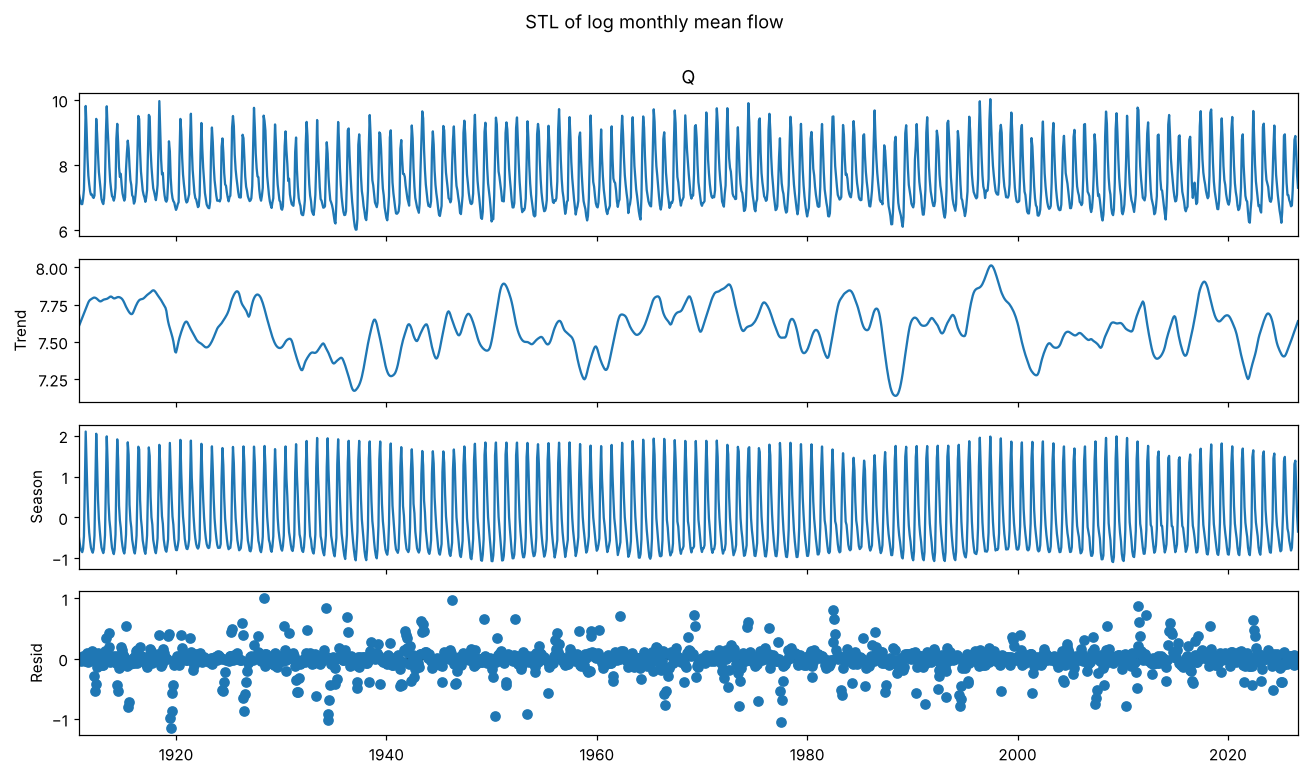

In [5]:
stl = STL(logm, period=12, robust=True).fit()
var_share = pd.Series({"trend": stl.trend.var(), "seasonal": stl.seasonal.var(), "remainder": stl.resid.var()})
print("Share of variance (log monthly flow):", (var_share / var_share.sum()).round(3).to_dict())
fig = stl.plot(); fig.set_size_inches(12, 7); fig.suptitle("STL of log monthly mean flow", y=1.0)
save(fig, "03_river_stl")

### 1.4 Stationarity

Annual features in levels and first differences; monthly log flow in levels, after a seasonal difference ($\Delta_{12}$), and after removing the monthly average; daily log-flow anomaly (log flow minus its average for that day of the year, divided by that day's standard deviation).

In [6]:
clim_mu = logQ.groupby(f["dowy"]).mean().rolling(15, center=True, min_periods=1).mean()
clim_sd = logQ.groupby(f["dowy"]).std().rolling(15, center=True, min_periods=1).mean()
z = (logQ - clim_mu.reindex(f["dowy"]).values) / clim_sd.reindex(f["dowy"]).values
deseas_m = logm - logm.groupby(logm.index.month).transform("mean")

river_series = {"log annual mean flow": np.log(ann["mean_Q"]), "log annual peak flow": np.log(ann["peak_Q"]),
                "centre of timing": ann["CT_dowy"], "log 7-day summer low flow": np.log(ann["low7_Q"])}
rows = []
for k, s in river_series.items():
    rows.append(stationarity(s, k)); rows.append(stationarity(s.diff(), "Δ " + k))
rows += [stationarity(logm, "log monthly flow"), stationarity(logm.diff(12), "Δ12 log monthly flow"),
         stationarity(deseas_m, "log monthly flow minus monthly mean"), stationarity(z.iloc[-3650:], "daily log-flow anomaly (last 10 years)")]
st_river = pd.DataFrame(rows).set_index("series")
st_river.to_csv(TAB / "P2_eda_stationarity_river.csv")
st_river

,n,"ADF p (lag 0, 1, 2)",KPSS p (level),KPSS p (trend),verdict
series,,,,,
log annual mean flow,116,"0.000, 0.000, 0.000",0.100,0.100,stationary
Δ log annual mean flow,115,"0.000, 0.000, 0.000",0.100,0.044,stationary
log annual peak flow,116,"0.000, 0.000, 0.000",0.100,0.100,stationary
Δ log annual peak flow,115,"0.000, 0.000, 0.000",0.042,0.010,unclear (tests disagree)
centre of timing,116,"0.000, 0.000, 0.000",0.010,0.026,unclear (tests disagree)
Δ centre of timing,115,"0.000, 0.000, 0.000",0.100,0.018,stationary
log 7-day summer low flow,116,"0.000, 0.000, 0.000",0.100,0.072,stationary
Δ log 7-day summer low flow,115,"0.000, 0.000, 0.000",0.100,0.010,stationary
log monthly flow,1392,"0.000, 0.000, 0.000",0.100,0.100,stationary


### 1.5 ACF and PACF

For the annual series, only lags up to about n/4 ≈ 25 are meaningful. For monthly flow, the raw ACF shows the 12-month cycle; after the seasonal difference, what remains is the short-term persistence plus a seasonal spike at lag 12. The daily anomaly decays slowly, the sign of a strongly persistent (AR-type) process.

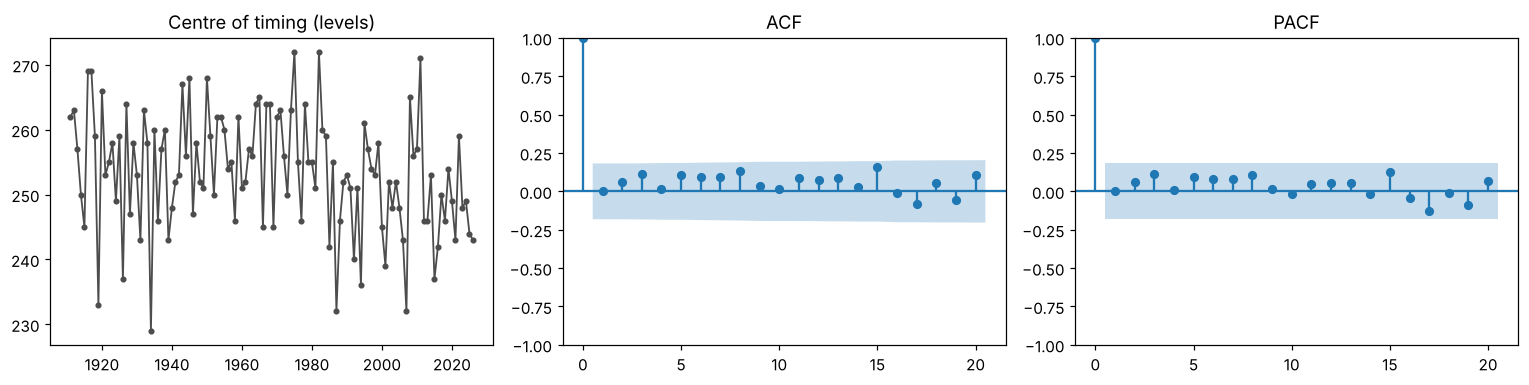

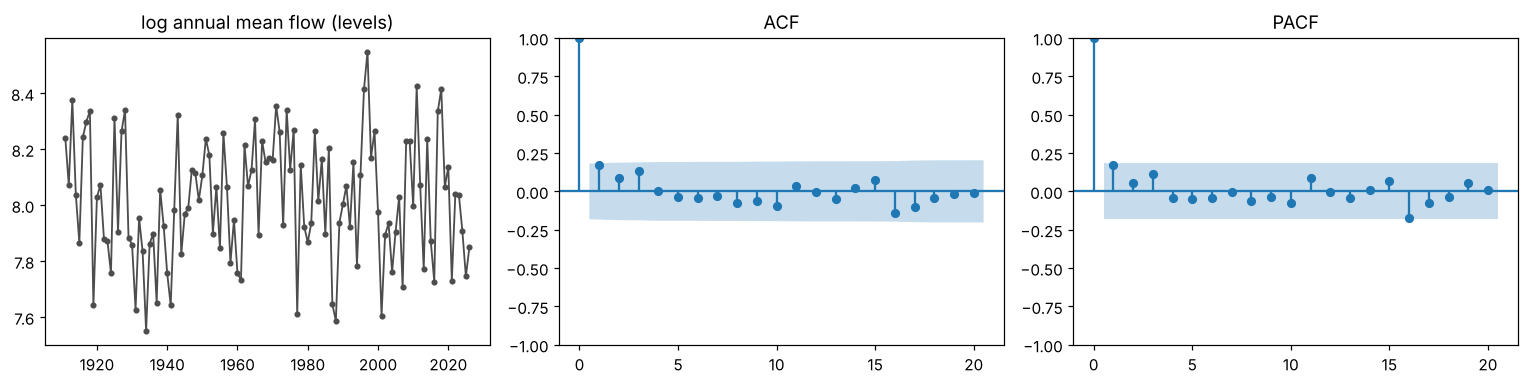

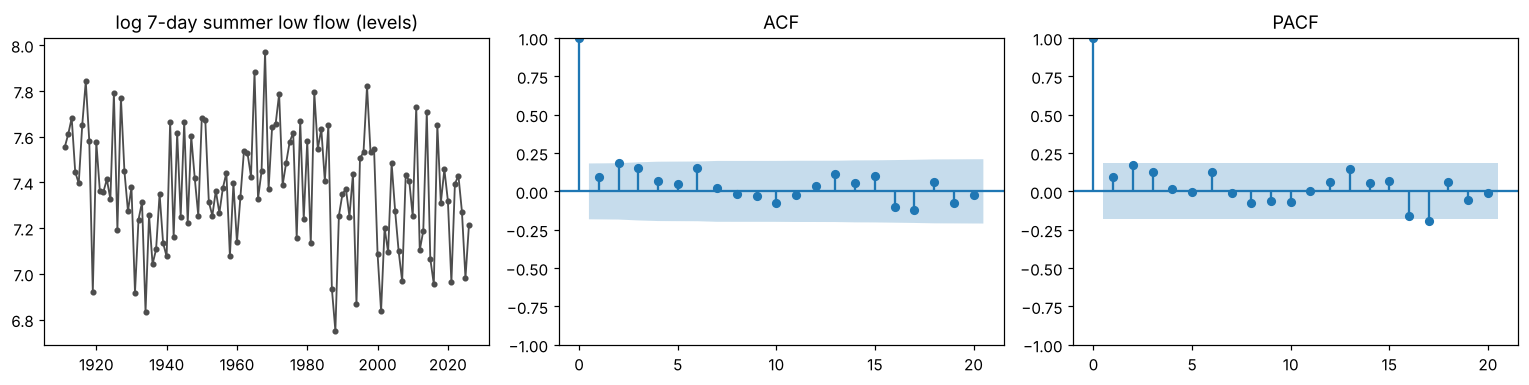

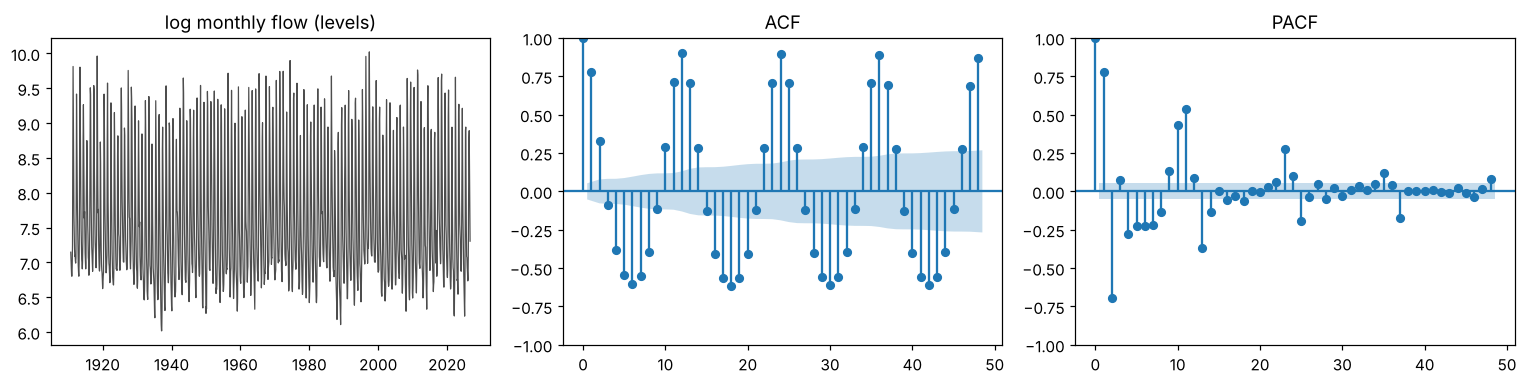

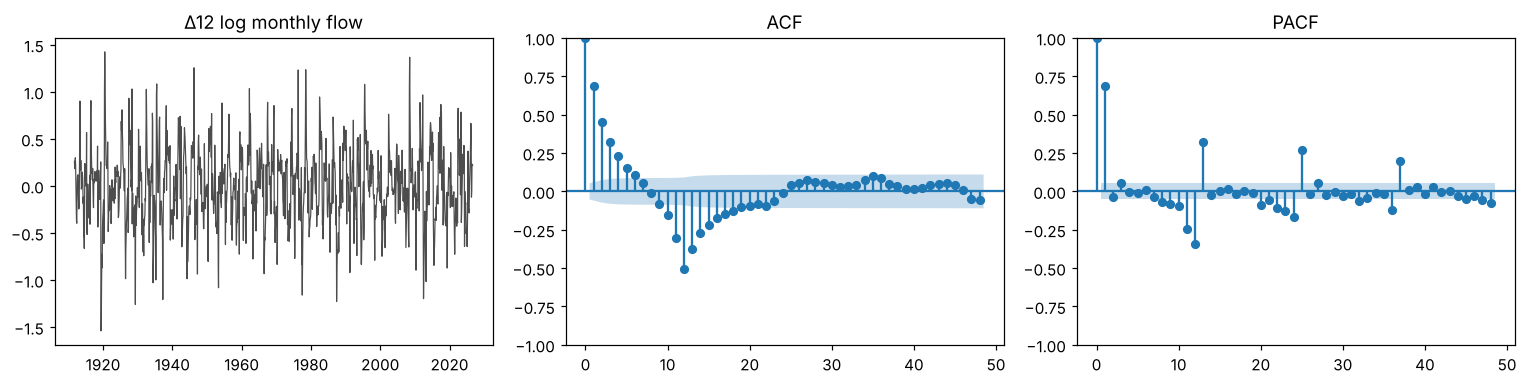

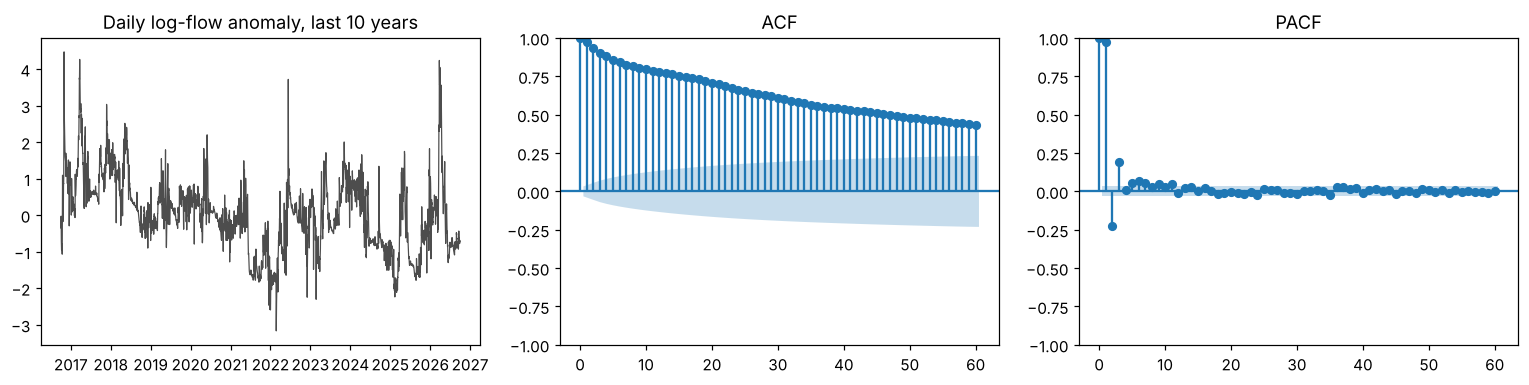

In [7]:
acf_pacf(ann["CT_dowy"], "Centre of timing (levels)", 20, "04_acf_ct")
acf_pacf(np.log(ann["mean_Q"]), "log annual mean flow (levels)", 20, "05_acf_meanflow")
acf_pacf(np.log(ann["low7_Q"]), "log 7-day summer low flow (levels)", 20, "06_acf_lowflow")
acf_pacf(logm, "log monthly flow (levels)", 48, "07_acf_monthly")
acf_pacf(logm.diff(12), "Δ12 log monthly flow", 48, "08_acf_monthly_d12")
acf_pacf(z.iloc[-3650:], "Daily log-flow anomaly, last 10 years", 60, "09_acf_daily_anomaly")

### 1.6 ARMA identification for the annual river series

Each stationary annual series is checked for short-term memory: is this year related to last year, beyond the long-run mean?

In [8]:
arma_rows, chosen = [], {}
for k in ["centre of timing", "log annual mean flow", "log 7-day summer low flow", "log annual peak flow"]:
    t, c = arma_id(river_series[k], k)
    arma_rows.append(t); chosen[k] = c
arma_river = pd.concat(arma_rows)
arma_river.to_csv(TAB / "P2_eda_arma_river.csv", index=False)
print("Chosen:", chosen)
arma_river.set_index(["series", "model"])

Chosen: {'centre of timing': 'ARMA(0,0)', 'log annual mean flow': 'ARMA(0,0)', 'log 7-day summer low flow': 'ARMA(0,0)', 'log annual peak flow': 'ARMA(0,0)'}


AIC    BIC  largest term p  all terms significant  Ljung–Box p  white-noise residuals  chosen
series                    model                                                                                                     
centre of timing          ARMA(0,0)  844.0  849.5           0.000                   True        0.635                   True    True
                          ARMA(1,0)  846.0  854.3           0.998                  False        0.541                   True   False
                          ARMA(2,0)  847.6  858.6           0.988                  False        0.613                   True   False
                          ARMA(0,1)  846.0  854.3           0.999                  False        0.540                   True   False
                          ARMA(0,2)  847.6  858.6           0.902                  False        0.590                   True   False
                          ARMA(1,1)  848.0  859.1           1.000                  False        0.440                   True   False
log annual mean flow      ARMA(0,0)  -19.0  -13.5           0.000                   True        0.472                   True    True
                          ARMA(1,0)  -20.6  -12.3           0.067                  False        0.881                   True   False
                          ARMA(2,0)  -19.0   -8.0           0.576                  False        0.851                   True   False
                          ARMA(0,1)  -20.3  -12.0           0.088                  False        0.848                   True   False
                          ARMA(0,2)  -18.5   -7.5           0.675                  False        0.801                   True   False
                          ARMA(1,1)  -19.5   -8.4           0.300                  False        0.892                   True   False
log 7-day summer low flow ARMA(0,0)   15.1   20.6           0.000                   True        0.264                   True    True
                          ARMA(1,0)   16.0   24.3           0.365                  False        0.430                   True   False
                          ARMA(2,0)   14.3   25.4           0.431                  False        0.648                   True   False
                          ARMA(0,1)   16.3   24.6           0.489                  False        0.368                   True   False
                          ARMA(0,2)   15.1   26.1           0.707                  False        0.570                   True   False
                          ARMA(1,1)   13.8   24.8           0.002                   True        0.696                   True   False
log annual peak flow      ARMA(0,0)   61.7   67.2           0.000                   True        0.991                   True    True
                          ARMA(1,0)   63.6   71.9           0.823                  False        0.982                   True   False
                          ARMA(2,0)   65.4   76.4           0.827                  False        0.971                   True   False
                          ARMA(0,1)   63.6   71.9           0.835                  False        0.982                   True   False
                          ARMA(0,2)   65.4   76.4           0.862                  False        0.971                   True   False
                          ARMA(1,1)   65.4   76.4           0.639                  False        0.968                   True   False

## 2. Snow

### 2.1 Daily snowpack and the typical snow season

Snow water equivalent (SWE) is the depth of water the snowpack would make if melted. Each station builds snow from October, peaks in April or May, and melts out by June; Parker Peak, the highest (9,420 ft), holds the most snow and melts last.

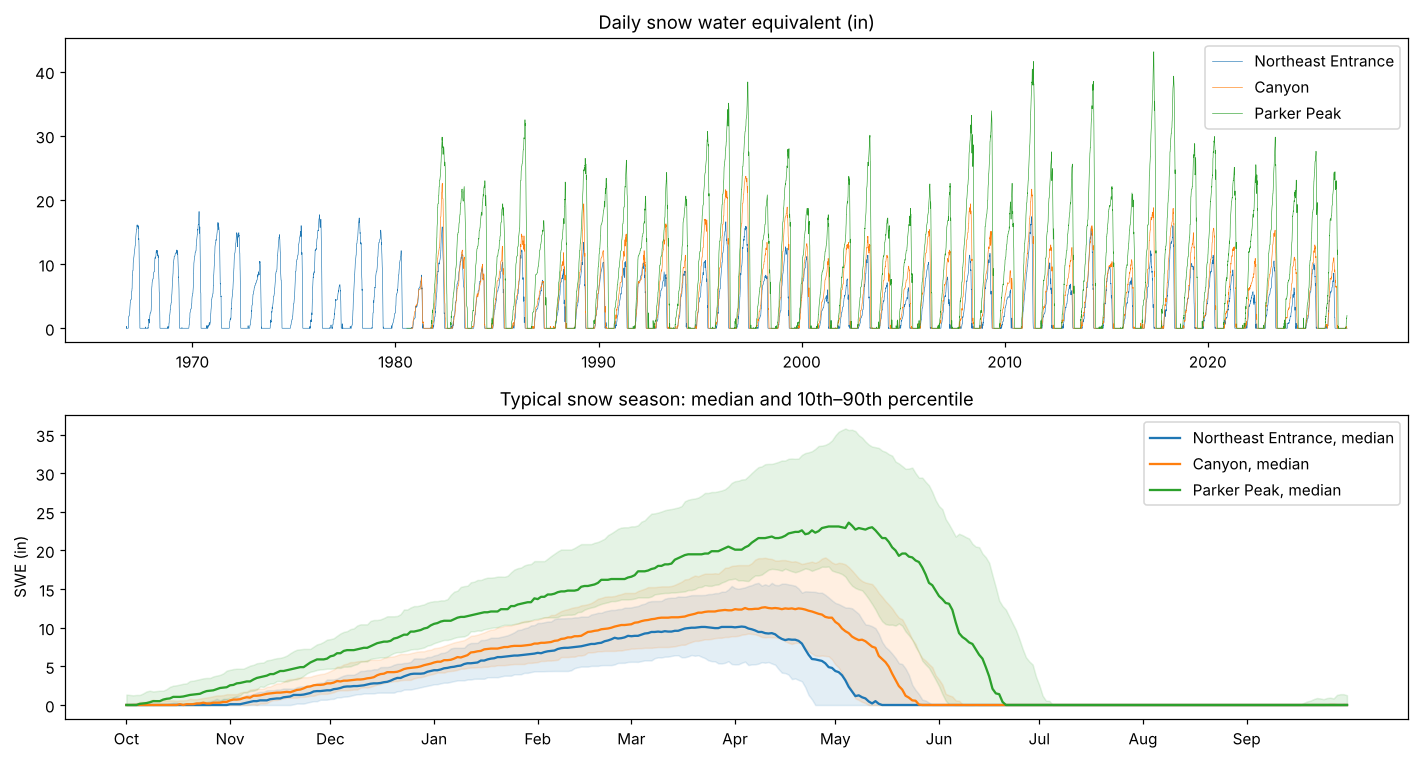

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
for i, (k, d) in enumerate(snow.items()):
    ax[0].plot(d.index, d["SWE"], lw=0.4, color=f"C{i}", label=k)
    clim = d.groupby("dowy")["SWE"].quantile([0.1, 0.5, 0.9]).unstack()
    ax[1].plot(clim.index, clim[0.5], color=f"C{i}", label=f"{k}, median")
    ax[1].fill_between(clim.index, clim[0.1], clim[0.9], color=f"C{i}", alpha=0.12)
ax[0].set_title("Daily snow water equivalent (in)"); ax[0].legend()
ticks = [1, 32, 62, 93, 124, 152, 183, 213, 244, 274, 305, 336]
ax[1].set_xticks(ticks, ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep"])
ax[1].set_title("Typical snow season: median and 10th–90th percentile"); ax[1].set_ylabel("SWE (in)"); ax[1].legend()
save(fig, "10_snow_daily")

### 2.2 Annual snow series and agreement between stations

The severity index combines the three stations (Canyon from 1981, Parker Peak from 1980; Northeast Entrance alone before that). Combining them only makes sense if the stations rise and fall together, so their annual peak SWE values are compared in levels and in year-to-year changes.

Annual peak SWE (in), summary:
                    count  mean  std   min   25%   50%   75%   max
Northeast Entrance   60.0  11.3  3.4   5.7   8.8  10.4  13.7  18.2
Canyon               46.0  14.1  3.9   7.3  11.4  13.1  15.9  23.7
Parker Peak          45.0  26.6  6.7  16.8  22.1  25.1  29.9  43.1

Correlation between stations, levels:
                    Northeast Entrance  Canyon  Parker Peak
Northeast Entrance                1.00    0.84         0.77
Canyon                            0.84    1.00         0.78
Parker Peak                       0.77    0.78         1.00

Correlation between stations, first differences:
                    Northeast Entrance  Canyon  Parker Peak
Northeast Entrance                1.00    0.84         0.83
Canyon                            0.84    1.00         0.85
Parker Peak                       0.83    0.85         1.00


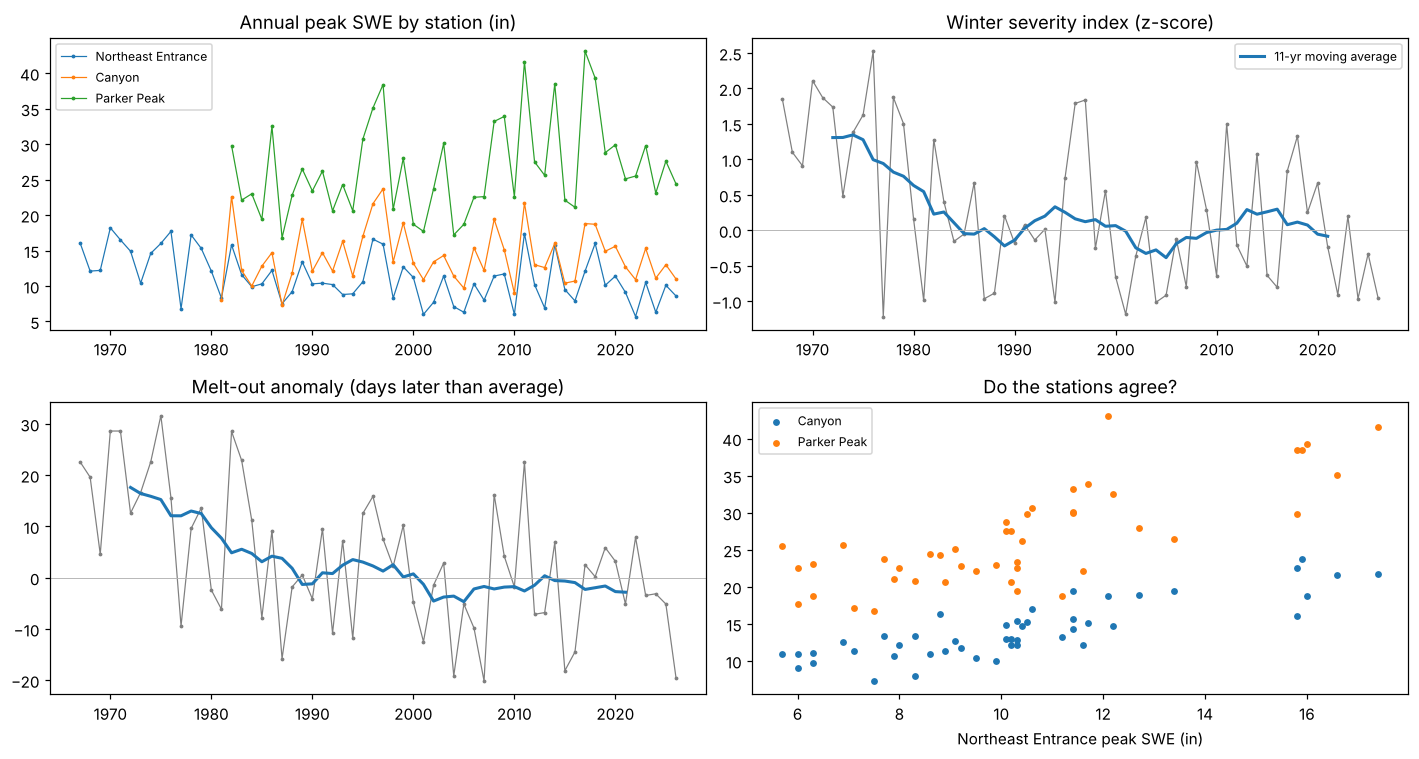

In [10]:
peak = pd.DataFrame({k: d.groupby("wy")["SWE"].max().where(d.groupby("wy")["SWE"].count() >= 300) for k, d in snow.items()}).loc[:2026]
print("Annual peak SWE (in), summary:"); print(peak.describe().round(1).T.to_string())
print("\nCorrelation between stations, levels:"); print(peak.dropna().corr().round(2).to_string())
print("\nCorrelation between stations, first differences:"); print(peak.dropna().diff().corr().round(2).to_string())

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for i, k in enumerate(peak):
    ax[0, 0].plot(peak.index, peak[k], ".-", lw=0.8, ms=3, color=f"C{i}", label=k)
ax[0, 0].set_title("Annual peak SWE by station (in)"); ax[0, 0].legend(fontsize=8)
s = sev["Severity_index"]
ax[0, 1].plot(s.index, s, ".-", color="0.5", lw=0.8, ms=3)
ax[0, 1].plot(s.index, s.rolling(11, center=True).mean(), color="C0", lw=2, label="11-yr moving average")
ax[0, 1].axhline(0, color="0.7", lw=0.6); ax[0, 1].set_title("Winter severity index (z-score)"); ax[0, 1].legend(fontsize=8)
m = sev["Melt_out_anom_days"]
ax[1, 0].plot(m.index, m, ".-", color="0.5", lw=0.8, ms=3)
ax[1, 0].plot(m.index, m.rolling(11, center=True).mean(), color="C0", lw=2)
ax[1, 0].axhline(0, color="0.7", lw=0.6); ax[1, 0].set_title("Melt-out anomaly (days later than average)")
ax[1, 1].scatter(peak["Northeast Entrance"], peak["Canyon"], s=12, label="Canyon")
ax[1, 1].scatter(peak["Northeast Entrance"], peak["Parker Peak"], s=12, label="Parker Peak")
ax[1, 1].set_xlabel("Northeast Entrance peak SWE (in)"); ax[1, 1].set_title("Do the stations agree?"); ax[1, 1].legend(fontsize=8)
save(fig, "11_snow_annual")

### 2.3 Monthly temperature

Monthly mean air temperature from the SNOTEL stations. The seasonal cycle (about 25 °C from January to July) is removed by subtracting each month's average, leaving the anomaly. SNOTEL temperature sensors were replaced in the 2000s and the new ones read warmer, so a step in the anomaly series is a known data artefact, not necessarily climate.

             count  mean   std    min   25%   50%   75%    max
Temp_mean_C  511.0  0.45  8.35 -16.42 -7.10 -0.26  7.92  16.90
Temp_anom_C  511.0 -0.14  1.88  -6.41 -1.27 -0.06  1.08   5.06


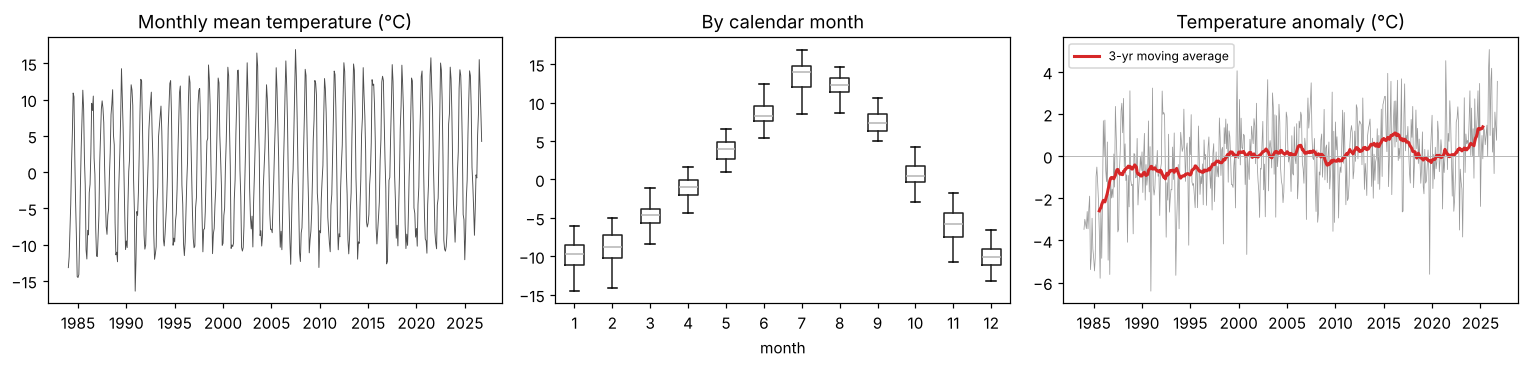

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(mtemp.index, mtemp["Temp_mean_C"], lw=0.6, color="0.3"); ax[0].set_title("Monthly mean temperature (°C)")
mtemp.assign(month=mtemp.index.month).boxplot(column="Temp_mean_C", by="month", ax=ax[1], grid=False, showfliers=False)
ax[1].set_title("By calendar month"); ax[1].set_xlabel("month"); fig.suptitle("")
ax[2].plot(mtemp.index, mtemp["Temp_anom_C"], lw=0.5, color="0.6")
ax[2].plot(mtemp.index, mtemp["Temp_anom_C"].rolling(36, center=True).mean(), color="C3", lw=2, label="3-yr moving average")
ax[2].axhline(0, color="0.7", lw=0.6); ax[2].set_title("Temperature anomaly (°C)"); ax[2].legend(fontsize=8)
save(fig, "12_temperature")
print(mtemp[["Temp_mean_C", "Temp_anom_C"]].describe().round(2).T.to_string())

### 2.4 Stationarity, ACF/PACF and ARMA identification for snow and temperature

In [12]:
snow_series = {"winter severity index (1982–)": sev["Severity_index"].loc[1982:],
               "melt-out anomaly (1982–)": sev["Melt_out_anom_days"].loc[1982:],
               "peak SWE Northeast Entrance (1967–)": peak["Northeast Entrance"].dropna(),
               "peak SWE Canyon": peak["Canyon"].dropna(), "peak SWE Parker Peak": peak["Parker Peak"].dropna()}
rows = []
for k, s in snow_series.items():
    rows.append(stationarity(s, k)); rows.append(stationarity(s.diff(), "Δ " + k))
rows += [stationarity(mtemp["Temp_mean_C"], "monthly temperature"), stationarity(mtemp["Temp_anom_C"], "monthly temperature anomaly")]
st_snow = pd.DataFrame(rows).set_index("series")
st_snow.to_csv(TAB / "P2_eda_stationarity_snow.csv")
st_snow

,n,"ADF p (lag 0, 1, 2)",KPSS p (level),KPSS p (trend),verdict
series,,,,,
winter severity index (1982–),45,"0.000, 0.000, 0.057",0.100,0.100,stationary
Δ winter severity index (1982–),44,"0.000, 0.000, 0.000",0.100,0.024,stationary
melt-out anomaly (1982–),45,"0.000, 0.000, 0.006",0.100,0.100,stationary
Δ melt-out anomaly (1982–),44,"0.000, 0.000, 0.000",0.100,0.010,stationary
peak SWE Northeast Entrance (1967–),60,"0.000, 0.000, 0.117",0.010,0.096,trend-stationary
Δ peak SWE Northeast Entrance (1967–),59,"0.000, 0.000, 0.000",0.100,0.100,stationary
peak SWE Canyon,46,"0.000, 0.000, 0.040",0.100,0.100,stationary
Δ peak SWE Canyon,45,"0.000, 0.000, 0.000",0.100,0.049,stationary
peak SWE Parker Peak,45,"0.000, 0.001, 0.062",0.095,0.100,stationary


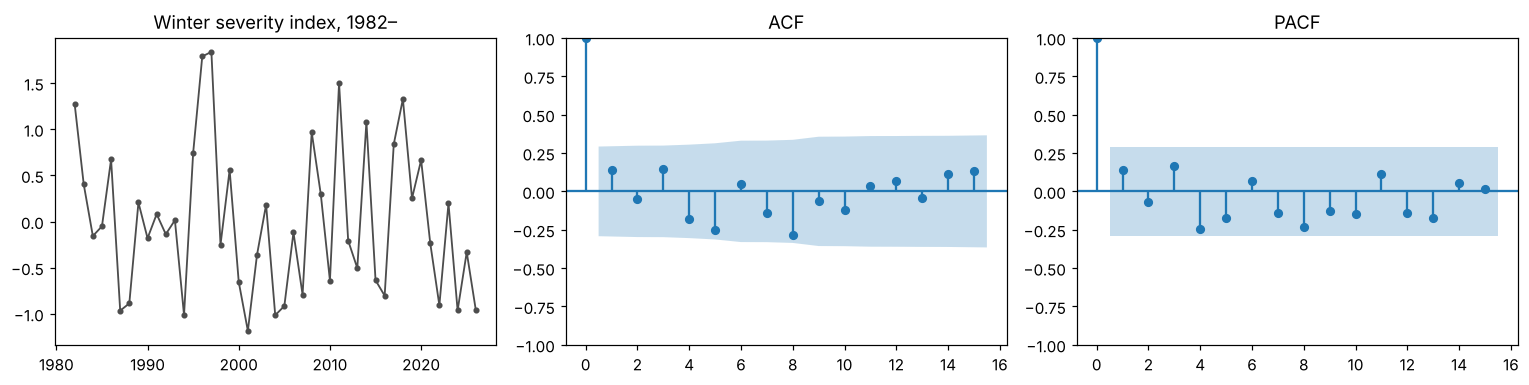

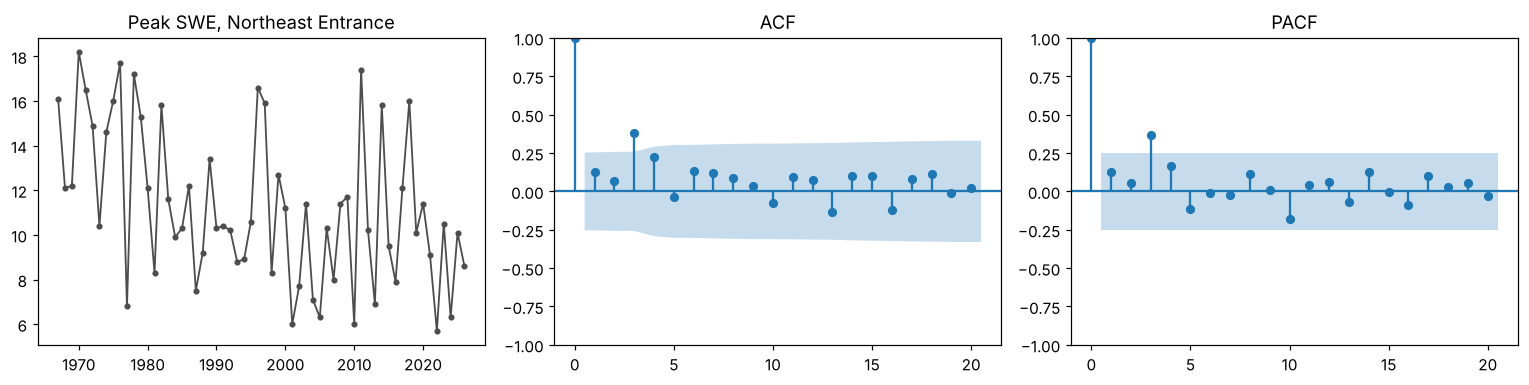

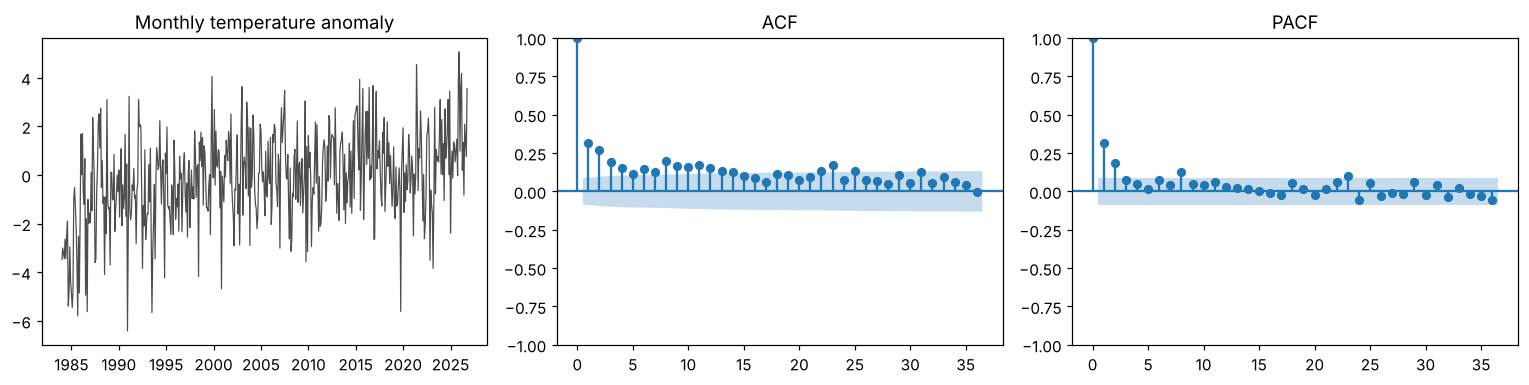

In [13]:
acf_pacf(sev["Severity_index"].loc[1982:], "Winter severity index, 1982–", 15, "13_acf_severity")
acf_pacf(peak["Northeast Entrance"].dropna(), "Peak SWE, Northeast Entrance", 20, "14_acf_peakswe")
acf_pacf(mtemp["Temp_anom_C"], "Monthly temperature anomaly", 36, "15_acf_temperature")

In [14]:
arma_rows, chosen_snow = [], {}
for k in ["winter severity index (1982–)", "melt-out anomaly (1982–)", "peak SWE Northeast Entrance (1967–)"]:
    t, c = arma_id(snow_series[k], k)
    arma_rows.append(t); chosen_snow[k] = c
t, c = arma_id(mtemp["Temp_anom_C"], "monthly temperature anomaly", cands=((0, 0), (1, 0), (2, 0), (0, 1), (1, 1), (2, 1)))
arma_rows.append(t); chosen_snow["monthly temperature anomaly"] = c
arma_snow = pd.concat(arma_rows)
arma_snow.to_csv(TAB / "P2_eda_arma_snow.csv", index=False)
print("Chosen:", chosen_snow)
arma_snow.set_index(["series", "model"])

Chosen: {'winter severity index (1982–)': 'ARMA(0,0)', 'melt-out anomaly (1982–)': 'ARMA(0,0)', 'peak SWE Northeast Entrance (1967–)': 'ARMA(0,0)', 'monthly temperature anomaly': 'ARMA(2,0)'}


AIC     BIC  largest term p  all terms significant  Ljung–Box p  white-noise residuals  chosen
series                              model                                                                                                       
winter severity index (1982–)       ARMA(0,0)   112.2   115.8           0.000                   True        0.149                   True    True
                                    ARMA(1,0)   113.3   118.7           0.325                  False        0.135                   True   False
                                    ARMA(2,0)   115.1   122.3           0.680                  False        0.096                   True   False
                                    ARMA(0,1)   113.1   118.5           0.188                  False        0.145                   True   False
                                    ARMA(0,2)   114.3   121.5           0.355                  False        0.179                   True   False
                                    ARMA(1,1)   113.7   121.0           0.138                  False        0.235                   True   False
melt-out anomaly (1982–)            ARMA(0,0)   351.7   355.3           0.000                   True        0.320                   True    True
                                    ARMA(1,0)   353.2   358.6           0.444                  False        0.259                   True   False
                                    ARMA(2,0)   354.7   361.9           0.550                  False        0.149                   True   False
                                    ARMA(0,1)   353.3   358.7           0.515                  False        0.266                   True   False
                                    ARMA(0,2)   353.2   360.4           0.588                  False        0.374                   True   False
                                    ARMA(1,1)   354.9   362.1           0.728                  False        0.177                   True   False
peak SWE Northeast Entrance (1967–) ARMA(0,0)   321.8   326.0           0.000                   True        0.066                   True    True
                                    ARMA(1,0)   322.8   329.1           0.300                  False        0.130                   True   False
                                    ARMA(2,0)   324.7   333.0           0.682                  False        0.078                   True   False
                                    ARMA(0,1)   322.9   329.2           0.290                  False        0.131                   True   False
                                    ARMA(0,2)   324.9   333.2           0.926                  False        0.093                   True   False
                                    ARMA(1,1)   320.2   328.6           0.000                   True        0.119                   True   False
monthly temperature anomaly         ARMA(0,0)  2097.1  2105.6           0.000                   True        0.000                  False   False
                                    ARMA(1,0)  2044.0  2056.7           0.000                   True        0.000                  False   False
                                    ARMA(2,0)  2027.9  2044.8           0.000                   True        0.072                   True    True
                                    ARMA(0,1)  2060.1  2072.8           0.000                   True        0.000                  False   False
                                    ARMA(1,1)  2014.6  2031.6           0.000                   True        0.002                  False   False
                                    ARMA(2,1)  2007.1  2028.3           0.002                   True        0.160                   True   False

## 3. Vegetation (NDVI)

### 3.1 Images, distribution and seasonal cycle

NDVI ranges from about 0 (snow, bare ground, water) to about 0.9 (dense green leaves). Each polygon shows the mountain growing season. The number of usable images per year rises sharply after 1999 (Landsat 7) and 2013 (Landsat 8), so early years rest on fewer images.

                      count   mean    std    min    25%    50%    75%    max
pair       side                                                             
Blacktail  riverside  590.0  0.394  0.140  0.039  0.294  0.409  0.504  0.698
           slope      590.0  0.334  0.134  0.011  0.236  0.331  0.441  0.718
Lamar      riverside  599.0  0.328  0.119 -0.022  0.253  0.342  0.410  0.662
           slope      599.0  0.380  0.135  0.009  0.283  0.375  0.482  0.746
Soda Butte riverside  599.0  0.343  0.124 -0.086  0.265  0.355  0.439  0.600
           slope      599.0  0.428  0.164 -0.043  0.316  0.426  0.560  0.757


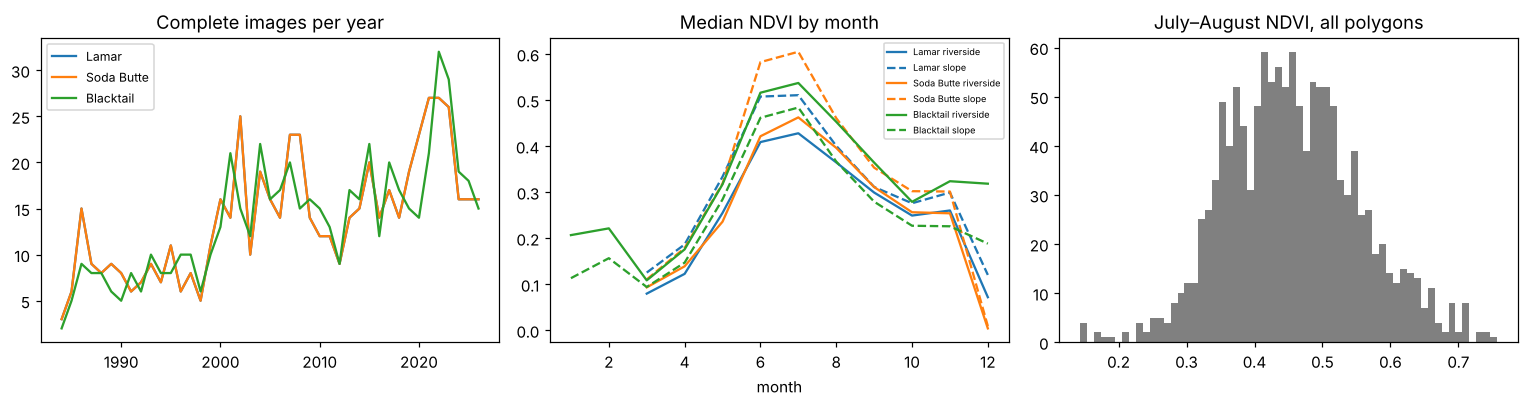

In [15]:
print(long.groupby(["pair", "side"])["ndvi"].describe().round(3).to_string())
imgs = long.drop_duplicates(["date", "pair"]).groupby(["year", "pair"]).size().unstack()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for p in PAIRS:
    ax[0].plot(imgs.index, imgs[p], color=COL[p], label=p)
ax[0].set_title("Complete images per year"); ax[0].legend(fontsize=8)
for p in PAIRS:
    for side, ls in [("riverside", "-"), ("slope", "--")]:
        d = long[(long.pair == p) & (long.side == side)]
        c = d.groupby("month")["ndvi"].median()
        ax[1].plot(c.index, c.values, ls, color=COL[p], label=f"{p} {side}")
ax[1].set_title("Median NDVI by month"); ax[1].set_xlabel("month"); ax[1].legend(fontsize=6)
ax[2].hist(long[long.month.isin([7, 8])]["ndvi"], bins=60, color="0.5"); ax[2].set_title("July–August NDVI, all polygons")
save(fig, "16_ndvi_images_season")

### 3.2 Annual July–August series

The annual value for each polygon is the median NDVI over all July–August images; the **riverside − slope** difference is computed on each image date before taking the median, as in notebook 11.

pair             Blacktail   Lamar  Soda Butte
side                                          
riverside count     42.000  43.000      43.000
          mean       0.489   0.410       0.442
          std        0.066   0.060       0.054
          min        0.290   0.318       0.336
          25%        0.457   0.365       0.416
          50%        0.489   0.408       0.436
          75%        0.531   0.444       0.480
          max        0.617   0.547       0.572
slope     count     42.000  43.000      43.000
          mean       0.421   0.456       0.536
          std        0.074   0.067       0.079
          min        0.259   0.348       0.404
          25%        0.368   0.393       0.470
          50%        0.420   0.454       0.532
          75%        0.472   0.509       0.595
          max        0.572   0.587       0.674
diff      count     42.000  43.000      43.000
          mean       0.068  -0.045      -0.088
          std        0.031   0.049       0.057
          min


Correlation of riverside − slope between streams (levels):
pair        Blacktail  Lamar  Soda Butte
pair                                    
Blacktail        1.00   0.11        0.09
Lamar            0.11   1.00        0.68
Soda Butte       0.09   0.68        1.00

Same, first differences:
pair        Blacktail  Lamar  Soda Butte
pair                                    
Blacktail        1.00   0.34        0.43
Lamar            0.34   1.00        0.53
Soda Butte       0.43   0.53        1.00


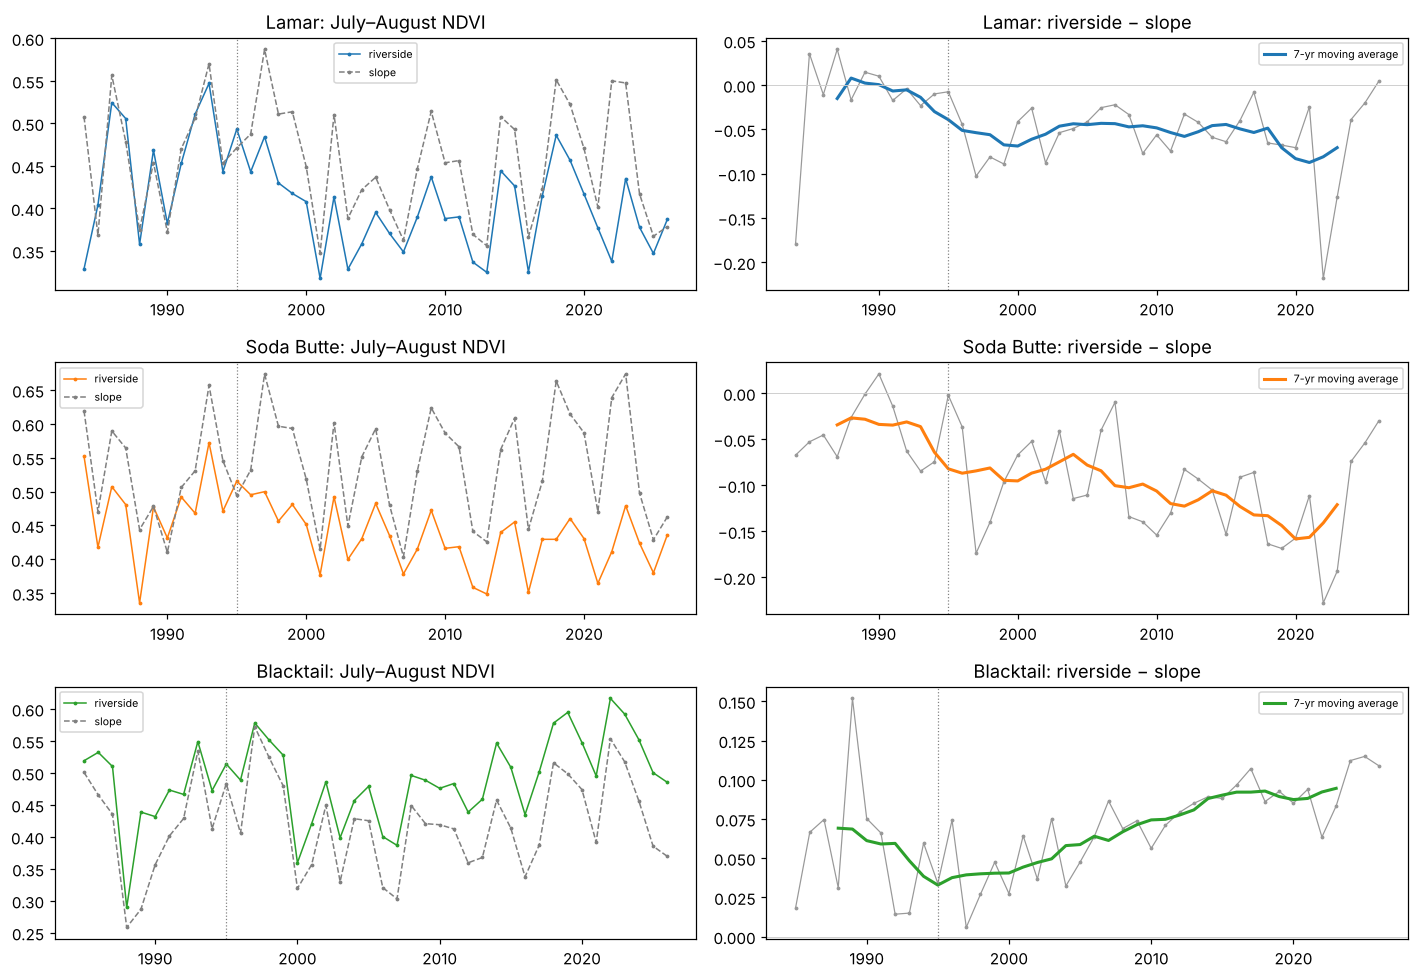

In [16]:
paired = long.pivot_table(index=["date", "pair"], columns="side", values="ndvi").dropna().reset_index()
paired["diff"] = paired["riverside"] - paired["slope"]
paired["year"], paired["month"] = paired.date.dt.year, paired.date.dt.month
vann = paired[paired.month.isin([7, 8])].groupby(["pair", "year"])[["riverside", "slope", "diff"]].median()
print(vann.groupby("pair").describe().round(3).T.to_string())

fig, ax = plt.subplots(3, 2, figsize=(13, 9))
for i, p in enumerate(PAIRS):
    d = vann.loc[p]
    ax[i, 0].plot(d.index, d["riverside"], ".-", color=COL[p], lw=1, ms=3, label="riverside")
    ax[i, 0].plot(d.index, d["slope"], ".--", color="0.5", lw=1, ms=3, label="slope")
    ax[i, 0].axvline(REINTRO, color="0.5", lw=0.8, ls=":"); ax[i, 0].set_title(f"{p}: July–August NDVI"); ax[i, 0].legend(fontsize=7)
    s = d["diff"]
    ax[i, 1].plot(s.index, s, ".-", color="0.6", lw=0.8, ms=3)
    ax[i, 1].plot(s.index, s.rolling(7, center=True).mean(), color=COL[p], lw=2, label="7-yr moving average")
    ax[i, 1].axvline(REINTRO, color="0.5", lw=0.8, ls=":"); ax[i, 1].axhline(0, color="0.8", lw=0.6)
    ax[i, 1].set_title(f"{p}: riverside − slope"); ax[i, 1].legend(fontsize=7)
save(fig, "17_ndvi_annual")
print("\nCorrelation of riverside − slope between streams (levels):")
print(vann["diff"].unstack(0).corr().round(2).to_string())
print("\nSame, first differences:")
print(vann["diff"].unstack(0).diff().corr().round(2).to_string())

### 3.3 Stationarity, ACF/PACF and ARMA identification

In [17]:
rows = []
for p in PAIRS:
    for col in ["riverside", "slope", "diff"]:
        s = vann.loc[p][col]
        rows.append(stationarity(s, f"{p} {col}")); rows.append(stationarity(s.diff(), f"Δ {p} {col}"))
st_veg = pd.DataFrame(rows).set_index("series")
st_veg.to_csv(TAB / "P2_eda_stationarity_vegetation.csv")
st_veg

,n,"ADF p (lag 0, 1, 2)",KPSS p (level),KPSS p (trend),verdict
series,,,,,
Lamar riverside,43,"0.000, 0.009, 0.143",0.056,0.100,stationary
Δ Lamar riverside,42,"0.000, 0.000, 0.000",0.057,0.010,stationary
Lamar slope,43,"0.000, 0.000, 0.007",0.100,0.100,stationary
Δ Lamar slope,42,"0.000, 0.000, 0.000",0.100,0.010,stationary
Lamar diff,43,"0.000, 0.023, 0.026",0.100,0.100,stationary
Δ Lamar diff,42,"0.000, 0.000, 0.000",0.100,0.100,stationary
Soda Butte riverside,43,"0.000, 0.013, 0.149",0.010,0.100,trend-stationary
Δ Soda Butte riverside,42,"0.000, 0.000, 0.000",0.100,0.013,stationary
Soda Butte slope,43,"0.000, 0.000, 0.000",0.100,0.100,stationary


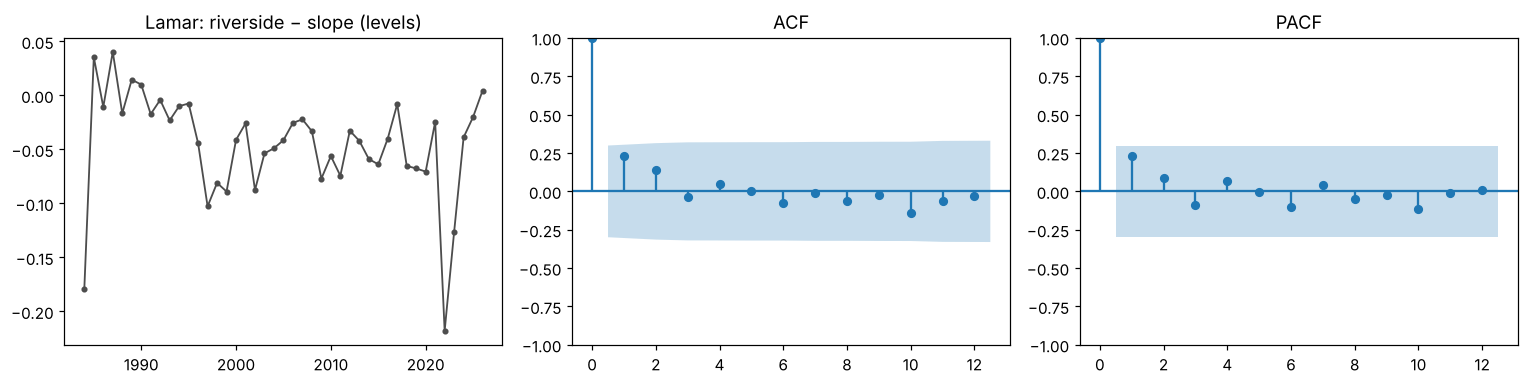

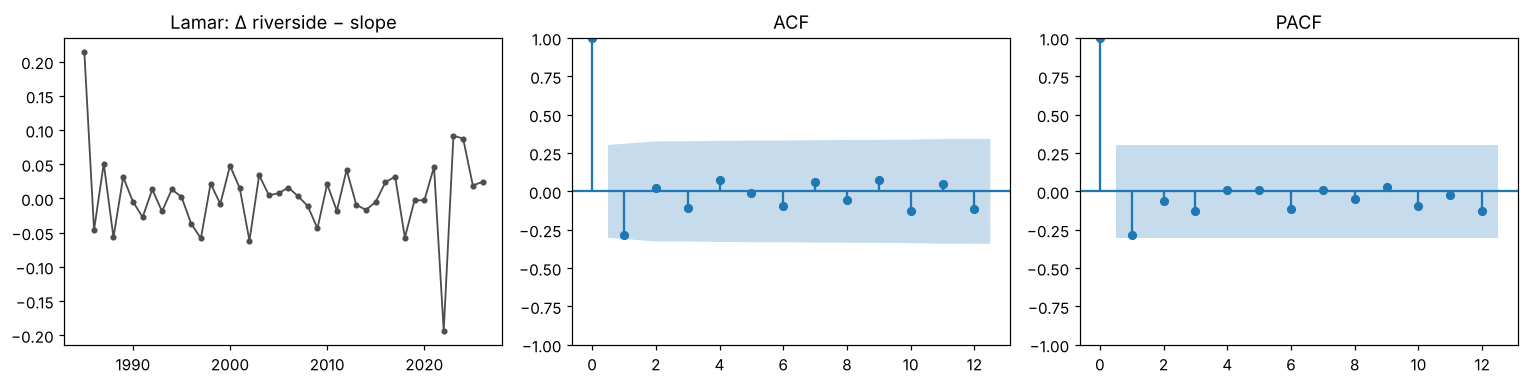

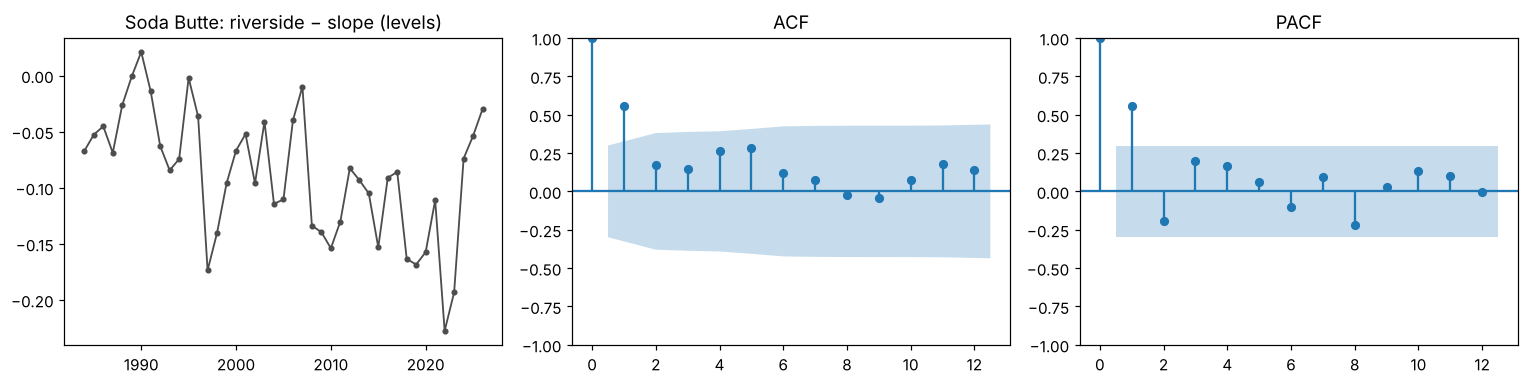

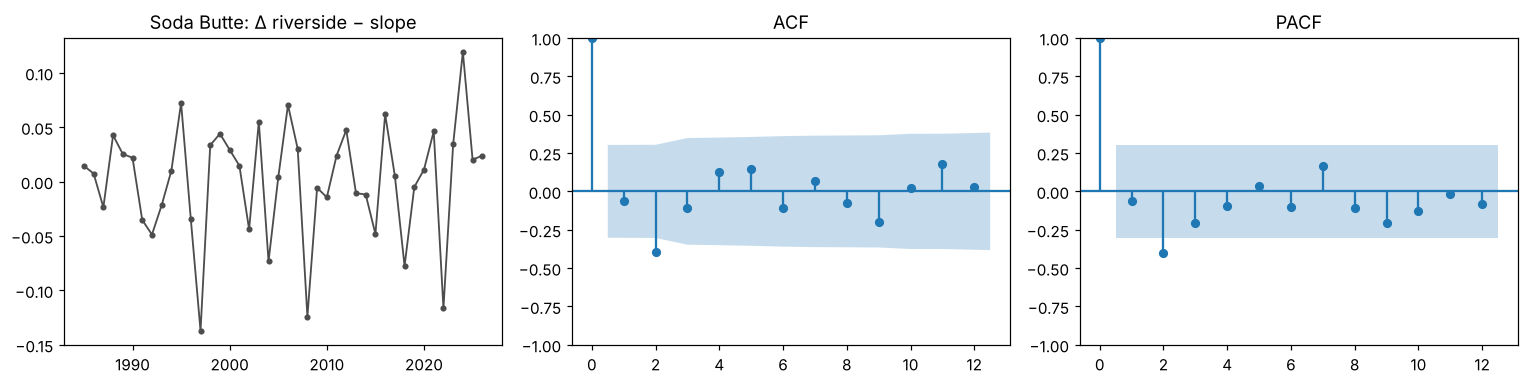

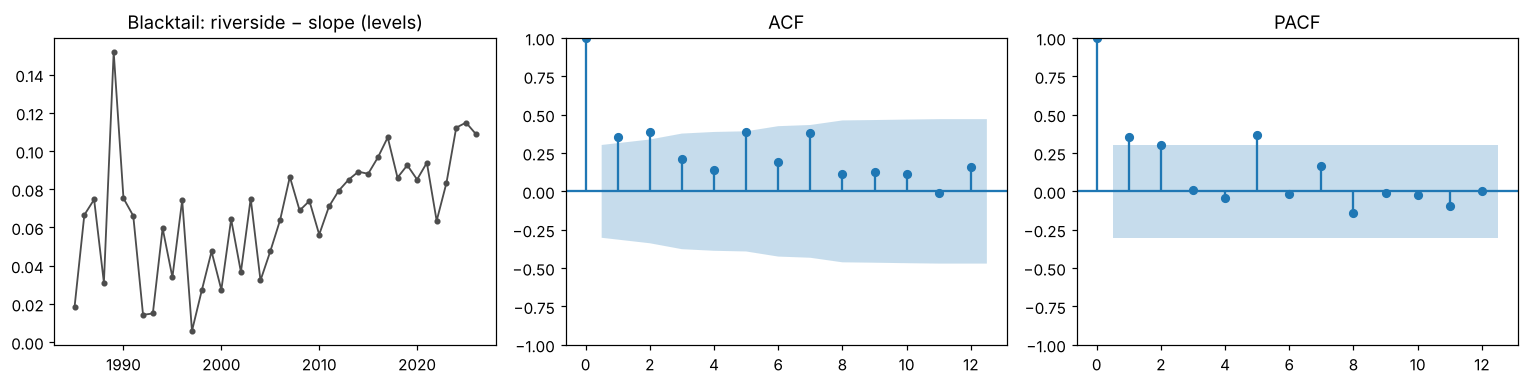

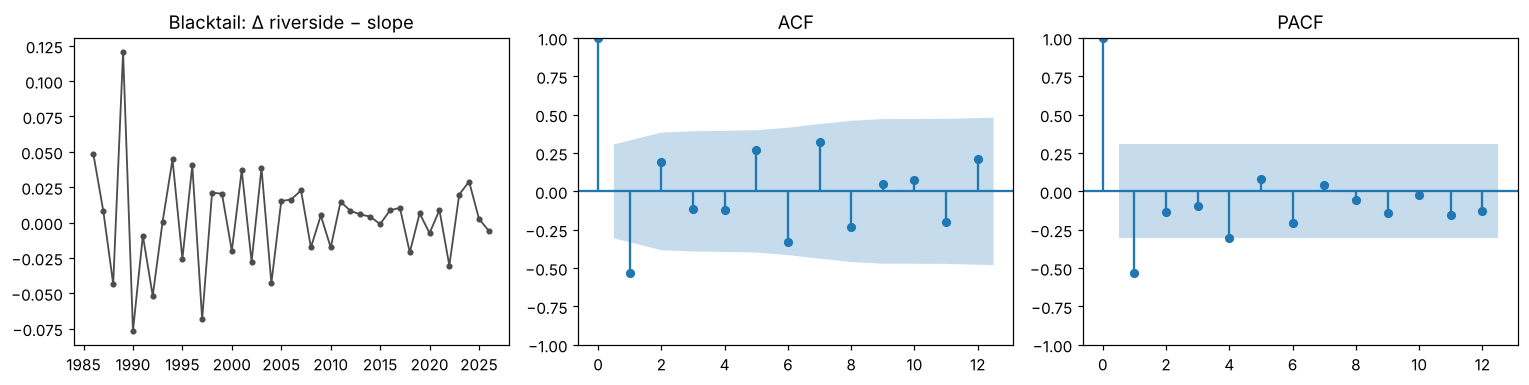

In [18]:
for p in PAIRS:
    s = vann.loc[p]["diff"]
    acf_pacf(s, f"{p}: riverside − slope (levels)", 12, f"18_acf_{p.lower().replace(' ', '')}")
    acf_pacf(s.diff(), f"{p}: Δ riverside − slope", 12, f"19_acf_{p.lower().replace(' ', '')}_diff")

The ARMA identification uses the form each series needs to be stationary (per the table above): levels where the series is stationary, first differences where it trends or wanders.

In [19]:
arma_rows, chosen_veg = [], {}
for p in PAIRS:
    s = vann.loc[p]["diff"]
    v = st_veg.loc[f"{p} diff", "verdict"]
    y, label = (s, f"{p} riverside − slope") if v == "stationary" else (s.diff(), f"Δ {p} riverside − slope")
    t, c = arma_id(y, label)
    arma_rows.append(t); chosen_veg[label] = c
arma_veg = pd.concat(arma_rows)
arma_veg.to_csv(TAB / "P2_eda_arma_vegetation.csv", index=False)
print("Chosen:", chosen_veg)
arma_veg.set_index(["series", "model"])

Chosen: {'Lamar riverside − slope': 'ARMA(0,0)', 'Δ Soda Butte riverside − slope': 'ARMA(0,0)', 'Δ Blacktail riverside − slope': 'ARMA(0,1)'}


AIC    BIC  largest term p  all terms significant  Ljung–Box p  white-noise residuals  chosen
series                         model                                                                                                     
Lamar riverside − slope        ARMA(0,0) -134.1 -130.6           0.000                   True        0.855                   True    True
                               ARMA(1,0) -135.0 -129.7           0.070                  False        0.965                   True   False
                               ARMA(2,0) -133.1 -126.1           0.741                  False        0.974                   True   False
                               ARMA(0,1) -134.4 -129.1           0.228                  False        0.939                   True   False
                               ARMA(0,2) -133.7 -126.6           0.188                  False        0.982                   True   False
                               ARMA(1,1) -133.0 -126.0           0.892                  False        0.955                   True   False
Δ Soda Butte riverside − slope ARMA(0,0) -124.0 -120.5           0.000                   True        0.204                   True    True
                               ARMA(1,0) -122.2 -117.0           0.770                  False        0.116                   True   False
                               ARMA(2,0) -127.3 -120.4           0.615                  False        0.426                   True   False
                               ARMA(0,1) -123.4 -118.2           0.001                   True        0.078                   True   False
                               ARMA(0,2) -134.4 -127.4           0.970                  False        0.671                   True   False
                               ARMA(1,1) -130.3 -123.4           0.967                  False        0.246                   True   False
Δ Blacktail riverside − slope  ARMA(0,0) -156.5 -153.0           0.000                   True        0.000                  False   False
                               ARMA(1,0) -168.6 -163.4           0.000                   True        0.419                   True   False
                               ARMA(2,0) -167.6 -160.8           0.145                  False        0.320                   True   False
                               ARMA(0,1) -173.0 -167.9           0.000                   True        0.420                   True    True
                               ARMA(0,2) -171.0 -164.2           0.880                  False        0.288                   True   False
                               ARMA(1,1) -171.0 -164.2           0.757                  False        0.263                   True   False

## 4. All annual series together

Correlations between levels of series that trend can be spurious, so first differences are shown next to levels (the same check the midsem notebook made for elk). Common years 1985–2025.

levels                                                                                                                   \
                    river CT log mean flow log low flow severity index melt-out anomaly veg diff Lamar veg diff Soda Butte veg diff Blacktail   
river CT                1.00          0.68         0.74           0.58             0.86          -0.41               -0.25              -0.09   
log mean flow           0.68          1.00         0.84           0.88             0.76          -0.35               -0.33              -0.10   
log low flow            0.74          0.84         1.00           0.73             0.69          -0.31               -0.31              -0.18   
severity index          0.58          0.88         0.73           1.00             0.75          -0.13               -0.13               0.02   
melt-out anomaly        0.86          0.76         0.69           0.75             1.00          -0.30               -0.15              -0.06   
veg diff Lamar         -0.41         -0.35        -0.31          -0.13            -0.30           1.00                0.77               0.08   
veg diff Soda Butte    -0.25         -0.33        -0.31          -0.13            -0.15           0.77                1.00               0.06   
veg diff Blacktail     -0.09         -0.10        -0.18           0.02            -0.06           0.08                0.06               1.00   

                    first differences                                                                                                                   
                             river CT log mean flow log low flow severity index melt-out anomaly veg diff Lamar veg diff Soda Butte veg diff Blacktail  
river CT                         1.00          0.69         0.80           0.59             0.88          -0.42               -0.17              -0.13  
log mean flow                    0.69          1.00         0.81           0.85             0.77          -0.40               -0.22               0.01  
log low flow                     0.80          0.81         1.00           0.68             0.70          -0.35               -0.24              -0.07  
severity index                   0.59          0.85         0.68           1.00             0.72          -0.15               -0.03               0.11  
melt-out anomaly                 0.88          0.77         0.70           0.72             1.00          -0.36               -0.05               0.04  
veg diff Lamar                  -0.42         -0.40        -0.35          -0.15            -0.36           1.00                0.62               0.35  
veg diff Soda Butte             -0.17         -0.22        -0.24          -0.03            -0.05           0.62                1.00               0.43  
veg diff Blacktail              -0.13          0.01        -0.07           0.11             0.04           0.35                0.43               1.00

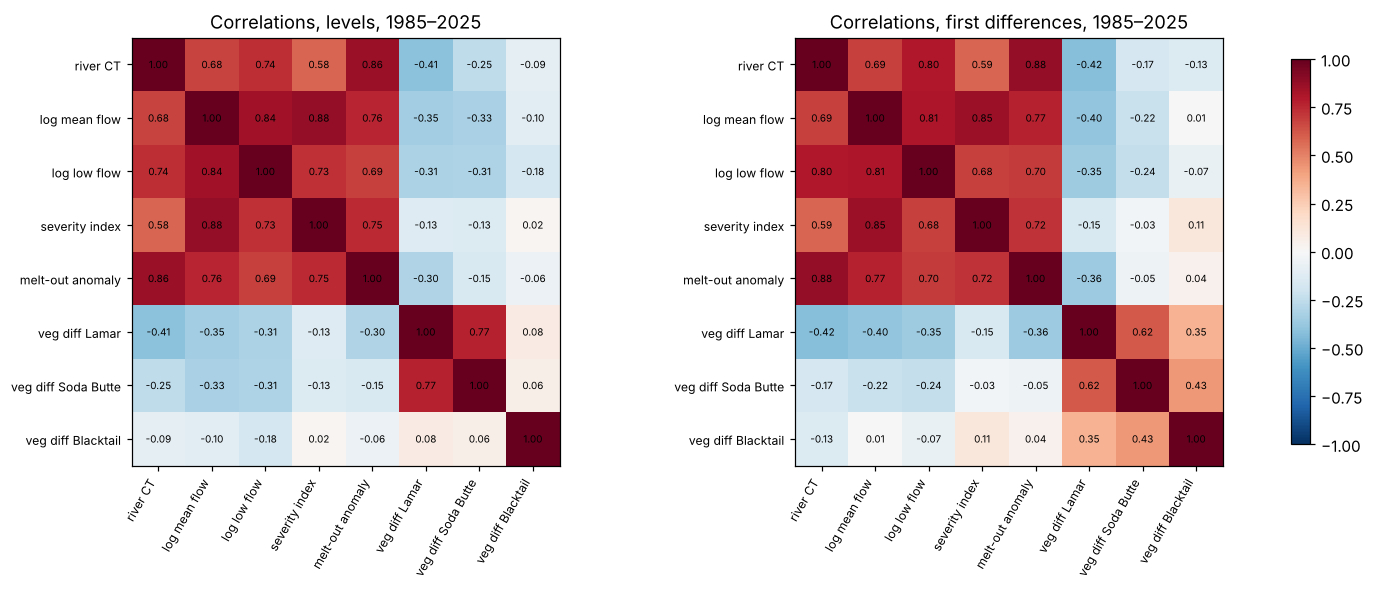

In [20]:
allann = pd.DataFrame({
    "river CT": ann["CT_dowy"], "log mean flow": np.log(ann["mean_Q"]), "log low flow": np.log(ann["low7_Q"]),
    "severity index": sev["Severity_index"], "melt-out anomaly": sev["Melt_out_anom_days"],
    **{f"veg diff {p}": vann.loc[p]["diff"] for p in PAIRS}}).loc[1985:2025]
lev, dif = allann.corr(), allann.diff().corr()
corr_tab = pd.concat({"levels": lev, "first differences": dif}, axis=1).round(2)
corr_tab.to_csv(TAB / "P2_eda_correlations.csv")
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
fig.subplots_adjust(wspace=0.55)
for a, M, ttl in [(ax[0], lev, "Levels"), (ax[1], dif, "First differences")]:
    im = a.imshow(M.values, cmap="RdBu_r", vmin=-1, vmax=1)
    a.set_xticks(range(len(M)), M.columns, rotation=60, ha="right", fontsize=8); a.set_yticks(range(len(M)), M.index, fontsize=8)
    for i in range(len(M)):
        for j in range(len(M)):
            a.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
    a.set_title(f"Correlations, {ttl.lower()}, 1985–2025")
fig.colorbar(im, ax=ax, shrink=0.7)
fig.savefig(FIG / "P2_EDA_20_correlations.png", dpi=200, bbox_inches="tight")
corr_tab

## 5. Takeaways

The table below collects every stationarity verdict; the points after it summarise what this notebook found.

In [21]:
summary = pd.concat([st_river, st_snow, st_veg])[["n", "verdict"]]
summary.to_csv(TAB / "P2_eda_stationarity_summary.csv")
print("ARMA chosen:", {**chosen, **chosen_snow, **chosen_veg})
summary

ARMA chosen: {'centre of timing': 'ARMA(0,0)', 'log annual mean flow': 'ARMA(0,0)', 'log 7-day summer low flow': 'ARMA(0,0)', 'log annual peak flow': 'ARMA(0,0)', 'winter severity index (1982–)': 'ARMA(0,0)', 'melt-out anomaly (1982–)': 'ARMA(0,0)', 'peak SWE Northeast Entrance (1967–)': 'ARMA(0,0)', 'monthly temperature anomaly': 'ARMA(2,0)', 'Lamar riverside − slope': 'ARMA(0,0)', 'Δ Soda Butte riverside − slope': 'ARMA(0,0)', 'Δ Blacktail riverside − slope': 'ARMA(0,1)'}


,n,verdict
series,,
log annual mean flow,116,stationary
Δ log annual mean flow,115,stationary
log annual peak flow,116,stationary
Δ log annual peak flow,115,unclear (tests disagree)
centre of timing,116,unclear (tests disagree)
Δ centre of timing,115,stationary
log 7-day summer low flow,116,stationary
Δ log 7-day summer low flow,115,stationary
log monthly flow,1392,stationary


**River**
1. Daily flow is strongly right-skewed (skewness 2.5, falling to 0.8 on the log scale), so all modelling uses log flow.
2. The yearly cycle is 92% of the variance of log monthly flow and the long-run trend only 3%; monthly models must handle the season first (notebook 12 uses a seasonal difference).
3. Annual mean, peak and summer low flow are stationary in levels. The centre of timing is not clearly stationary: ADF rejects a unit root but KPSS rejects stationarity around both a constant and a straight line, reflecting a slow drift to earlier melt since about 1980. Its first difference is stationary.
4. Every annual river series is white noise around its mean (ARMA(0,0) chosen): one year's value says almost nothing about the next. This is why notebook 12 finds no year-to-year carry-over.
5. The daily anomaly is strongly persistent: its ACF decays slowly over weeks, which motivates the AR / Ornstein–Uhlenbeck model in notebook 12.

**Snow**
6. The three SNOTEL stations agree closely (correlation of annual peak snow 0.77–0.84 in levels, 0.83–0.85 in year-to-year changes), so combining them into one severity index is justified.
7. The severity index, melt-out anomaly and peak snow at Canyon and Parker Peak are stationary. Peak snow at Northeast Entrance is trend-stationary (a declining trend since 1967), matching the trend found in notebook 12.
8. All annual snow series are white noise. Monthly temperature anomalies have short memory (AR(2), φ₁ = 0.26, φ₂ = 0.19), and their stationarity tests disagree because of warming and the SNOTEL sensor change.

**Vegetation**
9. Usable images per year rise sharply after 1999 and 2013, so early annual values rest on few images; 404 of 1,003 and 102 of 692 image dates were partial and dropped.
10. Riverside − slope is stationary on Lamar, and trend-stationary on Soda Butte (falling) and Blacktail (rising after 1995). Lamar and Soda Butte move together (r = 0.68), while Blacktail barely relates to either (r ≈ 0.1): the small willow creek behaves differently from the two braided rivers.
11. Lamar's difference and Soda Butte's year-to-year change are white noise. Blacktail's year-to-year change is MA(1) with θ = −0.80, a typical sign of differencing a series that is really a trend plus noise; notebook 11's Granger tests used the differenced form, which is still stationary but slightly less efficient.

**Across datasets**
12. Snow and river series are strongly correlated in both levels and differences (0.58–0.88), so the link is not just shared trends. The riverside − slope difference is negatively correlated with river flow and timing on Lamar (about −0.3 to −0.4) and weakly elsewhere, consistent with notebook 11's finding that wet summers green the slopes more than the always-wet riverside.